# I. Import libraries and check the dataset.
## 1. Import libraries



In [1]:

#1. Quản lý thư mục và dữ liệu
import os
import numpy as np
from pathlib import Path
from PIL import Image

#2. Trực quan hóa
import matplotlib.pyplot as plt

#3. TensorFlow và Keras
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

#4. Chia dữ liệu và đánh giá mô hình
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

#5. Transfer Learning
from tensorflow.keras.applications import ResNet50, MobileNetV2

#Kiểm tra môi trường
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


## 2. Declare the dataset

In [2]:
# Đọc dữ liệu
data_dir = Path("../midterm - prj1/x-ray chest")
class_names = ["NORMAL", "PNEUMONIA", "COVID"]
IMAGE_EXTENSIONS = {".png"}

X, y = [], []
class_counts = {}  # lưu tổng số ảnh mỗi class

for label, name in enumerate(class_names):
    folder = data_dir / name

    image_files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    class_counts[name] = len(image_files)

    for path in image_files:
        img = Image.open(path).convert("L")  # chuyển sang ảnh xám, 1 kênh
        img = img.resize((128, 128))         # đưa về cùng kích thước

        X.append(np.array(img))
        y.append(label)

# Chuyển sang mảng để train model
X = np.array(X, dtype=np.uint8)
y = np.array(y)

# In số ảnh mỗi class
for name, count in class_counts.items():
    print(f"  {name}: {count} ảnh")
print(f"Tổng: {sum(class_counts.values())} ảnh")

print("X shape:", X.shape)
print("y shape:", y.shape)

  NORMAL: 1802 ảnh
  PNEUMONIA: 1800 ảnh
  COVID: 1626 ảnh
Tổng: 5228 ảnh
X shape: (5228, 128, 128)
y shape: (5228,)


# II. Data Preparation
## 1. Split train/test and Normalize image

In [3]:
# Chia train, validation, test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Reshape và chuẩn hóa pixel về khoảng 0–1
X_train = X_train.reshape(-1, 128, 128, 1).astype("float32") / 255.0
X_val = X_val.reshape(-1, 128, 128, 1).astype("float32") / 255.0
X_test = X_test.reshape(-1, 128, 128, 1).astype("float32") / 255.0

# Chuyển nhãn sang one-hot coding
Y_train = to_categorical(y_train, 3)
Y_val = to_categorical(y_val, 3)
Y_test = to_categorical(y_test, 3)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (3659, 128, 128, 1)
Validation: (784, 128, 128, 1)
Test: (785, 128, 128, 1)


## 2. Build simple CNN model

In [4]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D
from keras.layers import Dense, Flatten, Dropout

# Định nghĩa model
model = Sequential()

# Thêm Convolutional Layer với 32 kernel, kích thước kernel 3*3
# dùng hàm relu làm hàm kích hoạt cho lớp đầu tiên
model.add(Conv2D(32, (3, 3), activation="relu",
                 input_shape=(128, 128, 1)))

# Thêm Convolutional Layer
model.add(Conv2D(32, (3, 3), activation="relu"))

# Thêm Max pooling Layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten Layer chuyển từ tensor sang vector
model.add(Flatten())

# Thêm Fully Connected Layer với 128 nodes và dùng hàm relu
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.5))

# Output Layer có 3 node và dùng softmax function để chuyển sang xác suất
model.add(Dense(3, activation="softmax"))

# Compile model
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

c:\Users\Laptop\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 124, 124, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 123008)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    15,745,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,755,107 (60.10 MB)

 Trainable params: 15,755,107 (60.10 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Training model
H = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    batch_size=32,
    epochs=10,
    verbose=1
)

# Đánh giá trên tập test
score = model.evaluate(X_test, Y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 104s 870ms/step - accuracy: 0.7939 - loss: 0.6289 - val_accuracy: 0.9222 - val_loss: 0.2168
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 149s 935ms/step - accuracy: 0.9145 - loss: 0.2289 - val_accuracy: 0.9388 - val_loss: 0.1733
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 138s 894ms/step - accuracy: 0.9396 - loss: 0.1800 - val_accuracy: 0.9388 - val_loss: 0.1698
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 83s 723ms/step - accuracy: 0.9563 - loss: 0.1252 - val_accuracy: 0.9477 - val_loss: 0.1467
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 95s 828ms/step - accuracy: 0.9699 - loss: 0.0917 - val_accuracy: 0.9490 - val_loss: 0.1384
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 115s 996ms/step - accuracy: 0.9721 - loss: 0.0829 - val_accuracy: 0.9566 - val_loss: 0.1418
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 106s 918ms/step - accuracy: 0.9817 - loss: 0.0623 - val_accuracy: 0.9579 - val_loss: 0.1514
Epoch 8/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 142s 916ms/step - accuracy: 0.9825 - l

25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 120ms/step
Accuracy: 0.28662420382165604
              precision    recall  f1-score   support

      NORMAL     0.3155    0.6531    0.4255       271
   PNEUMONIA     0.2143    0.1778    0.1943       270
       COVID     0.0000    0.0000    0.0000       244

    accuracy                         0.2866       785
   macro avg     0.1766    0.2770    0.2066       785
weighted avg     0.1826    0.2866    0.2137       785



c:\Users\Laptop\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Laptop\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Laptop\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


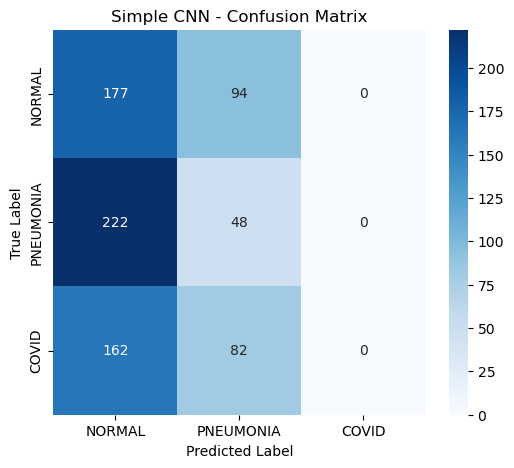

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score
import seaborn as sns

# Dự đoán trên tập test
Y_pred = model.predict(X_test)

# Chuyển xác suất sang nhãn
y_pred = np.argmax(Y_pred, axis=1)
y_true = y_test  # y_test chứa nhãn dạng số nguyên

# Accuracy
print("Accuracy:", accuracy_score(y_true, y_pred))

# Precision, Recall, F1-score
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Simple CNN - Confusion Matrix")
plt.show()